## 11\_modele\_test\_strasbourg

# 11 · Validation du modèle sur Strasbourg

Évaluation hors échantillon sur une agglomération entière non vue à l'apprentissage, afin d'éviter la fuite d'information entre carreaux voisins.

1. Apprentissage sur tous les réseaux Citiz sauf Citiz Grand Est, sans aucun carreau de l'Eurométropole.
2. Prédiction sur les carreaux de l'Eurométropole situés dans une commune desservie par Citiz.
3. Mesures : AUC, part des stations réelles captées par les 5 % et 10 % de carreaux les mieux notés, et la même mesure étendue aux carreaux voisins.
4. Référence : modèle naïf classant les carreaux par population seule.

Le modèle principal (régression logistique) est fixé avant l'évaluation. Le gradient boosting n'intervient qu'à titre de comparaison.

**Sorties :** tables `resultats_modele` et `importance_variables` ; expérience MLflow `citiz_test_strasbourg`.

In [ ]:
# 1. Dépendances
%pip install -q geopandas pyogrio py7zr

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# 2. Outils communs
import os, re, glob, shutil, tempfile, zipfile, warnings
import numpy as np
import pandas as pd
from pyproj import Transformer
warnings.filterwarnings("ignore")

BASE = "/lakehouse/default/Files"
if not os.path.isdir(BASE):
    raise RuntimeError("Lakehouse par défaut non attaché : attacher le Lakehouse mobilite au notebook.")
BRUT = os.path.join(BASE, "brut")
TRAITE = os.path.join(BASE, "traite")
CARTES = os.path.join(TRAITE, "cartes")
os.makedirs(CARTES, exist_ok=True)

# Conversions entre systèmes de coordonnées : 3035 = grille INSEE, 2154 = Lambert-93 (mètres), 4326 = GPS
T_3035_2154 = Transformer.from_crs(3035, 2154, always_xy=True)
T_3035_4326 = Transformer.from_crs(3035, 4326, always_xy=True)
T_4326_3035 = Transformer.from_crs(4326, 3035, always_xy=True)
T_4326_2154 = Transformer.from_crs(4326, 2154, always_xy=True)

def _copier_csv(df, chemin):
    """Écrit le CSV en local, puis le copie dans le Lakehouse. Écrire directement dans OneLake échoue parfois
    quand le fichier existe déjà (« Unable to rename file »)."""
    fd, tmp = tempfile.mkstemp(suffix=".csv")
    os.close(fd)
    try:
        df.to_csv(tmp, index=False)
        if os.path.exists(chemin):
            os.remove(chemin)
        shutil.copyfile(tmp, chemin)
    finally:
        os.remove(tmp)

def _adresse_table(nom):
    """Adresse OneLake de la table dans le Lakehouse attaché, dans le schéma dbo s'il existe."""
    import notebookutils
    ctx = notebookutils.runtime.context
    espace = ctx.get("defaultLakehouseWorkspaceId") or ctx.get("currentWorkspaceId")
    lakehouse = ctx.get("defaultLakehouseId")
    if not (espace and lakehouse):
        raise RuntimeError("Lakehouse par défaut introuvable : attacher le Lakehouse mobilite au notebook")
    schema = "/dbo" if os.path.isdir("/lakehouse/default/Tables/dbo") else ""
    return f"abfss://{espace}@onelake.dfs.fabric.microsoft.com/{lakehouse}/Tables{schema}/{nom}"

def _ecrire_table(df, nom):
    """Table Delta lue par Power BI. Noyau Spark : saveAsTable. Noyau Python : bibliothèque deltalake."""
    try:
        spark  # n'existe que dans le noyau Spark
    except NameError:
        import pyarrow as pa
        import notebookutils
        from deltalake import write_deltalake
        donnees = pa.Table.from_pandas(df, preserve_index=False)
        options = {"bearer_token": notebookutils.credentials.getToken("storage"), "use_fabric_endpoint": "true"}
        try:
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", schema_mode="overwrite",
                            storage_options=options)
        except TypeError:   # anciennes versions de deltalake
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", overwrite_schema=True,
                            storage_options=options)
        return
    spark.createDataFrame(df).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(nom)

def enregistrer(df, nom):
    """Enregistre un tableau en CSV dans Files/traite (relu par les autres notebooks)
    et en table du Lakehouse (lue par Power BI), avec le noyau Python comme avec le noyau Spark."""
    df = df.reset_index(drop=True).copy()
    _copier_csv(df, os.path.join(TRAITE, nom + ".csv"))
    for c in df.columns:
        if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c])):
            df[c] = df[c].map(lambda v: None if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
    try:
        _ecrire_table(df, nom)
        print(f"   table {nom} : {len(df)} lignes (copie dans Files/traite/{nom}.csv)")
    except Exception as e:
        print(f"   {nom}.csv : {len(df)} lignes. ATTENTION, table non créée pour Power BI : {e}")

def nb(n):
    """Écrit un nombre avec des espaces entre les milliers : 12 345."""
    return f"{n:,.0f}".replace(",", " ")

def lire(nom):
    """Relit un tableau enregistré par un autre notebook."""
    chemin = os.path.join(TRAITE, nom + ".csv")
    if not os.path.exists(chemin):
        raise FileNotFoundError(f"{nom}.csv introuvable dans Files/traite : exécuter d'abord le notebook qui le produit.")
    return pd.read_csv(chemin, dtype={"idcar": str, "commune": str, "idcar_1km": str, "candidat": str})

COLONNES_FILOSOFI = ["idcar_200m", "idcar_1km", "i_est_200", "lcog_geo", "ind", "men", "men_pauv", "men_1ind",
                     "men_5ind", "men_prop", "men_fmp", "ind_snv", "men_surf", "men_coll", "men_mais", "log_av45",
                     "log_45_70", "log_70_90", "log_ap90", "log_inc", "log_soc", "ind_0_3", "ind_4_5", "ind_6_10",
                     "ind_11_17", "ind_18_24", "ind_25_39", "ind_40_54", "ind_55_64", "ind_65_79", "ind_80p", "ind_inc"]
TEXTE_FILOSOFI = ["idcar_200m", "idcar_1km", "lcog_geo"]

def charger_filosofi():
    """Carreaux de 200 m de métropole (CSV ou GeoPackage), avec leur centre en coordonnées 3035."""
    csvs = sorted(glob.glob(os.path.join(BRUT, "filosofi", "**", "*.csv"), recursive=True),
                  key=os.path.getsize, reverse=True)
    csvs = [c for c in csvs if "met" in os.path.basename(c).lower()] or csvs
    if csvs:
        source = csvs[0]
        with open(source, encoding="utf-8", errors="replace") as f:
            entete = f.readline()
        sep = ";" if entete.count(";") > entete.count(",") else ","
        noms = [c.strip().strip('"') for c in entete.strip().split(sep)]
        utiles = [c for c in noms if c.lower() in COLONNES_FILOSOFI]
        df = pd.read_csv(source, sep=sep, usecols=utiles,
                         dtype={c: str for c in utiles if c.lower() in TEXTE_FILOSOFI})
    else:
        gpkgs = [g for g in glob.glob(os.path.join(BRUT, "**", "*.gpkg"), recursive=True)
                 if "carreaux" in os.path.basename(g).lower() and "met" in os.path.basename(g).lower()]
        if not gpkgs:
            raise FileNotFoundError("Carreaux Filosofi introuvables dans Files/brut/filosofi (notebook 01).")
        import pyogrio
        source = gpkgs[0]
        df = pyogrio.read_dataframe(source, read_geometry=False)
    df.columns = [c.lower() for c in df.columns]
    df = df[[c for c in COLONNES_FILOSOFI if c in df.columns]].copy()
    for c in df.columns:
        if c not in TEXTE_FILOSOFI and not pd.api.types.is_numeric_dtype(df[c]):   # décimales avec une virgule
            df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    nombres = [c for c in df.columns if c not in TEXTE_FILOSOFI]
    df[nombres] = df[nombres].fillna(0)
    # L'identifiant INSPIRE donne le coin sud-ouest du carreau en mètres : CRS3035RES200mN<nord>E<est>
    ne = df["idcar_200m"].astype(str).str.extract(r"CRS3035RES200mN(\d+)E(\d+)").astype(float)
    df["x3035"], df["y3035"] = ne[1] + 100, ne[0] + 100
    df = df.dropna(subset=["x3035", "y3035"])
    df["ix"] = ((df["x3035"] - 100) // 200).astype("int64")
    df["iy"] = ((df["y3035"] - 100) // 200).astype("int64")
    df["commune"] = df["lcog_geo"].astype(str).str[:5]
    df = df.rename(columns={"idcar_200m": "idcar"}).reset_index(drop=True)
    print(f"Filosofi : {nb(len(df))} carreaux de métropole lus ({os.path.basename(source)})")
    return df

def trouver_admin_express():
    """GeoPackage ADMIN EXPRESS : déjà extrait, ou extrait de l'archive .7z déposée dans Files/brut."""
    gpkgs = [g for g in glob.glob(os.path.join(BRUT, "**", "*.gpkg"), recursive=True)
             if "ADE" in os.path.basename(g).upper() or "ADMIN" in os.path.basename(g).upper()]
    if gpkgs:
        return gpkgs[0]
    archives = [a for a in glob.glob(os.path.join(BRUT, "**", "*.7z"), recursive=True) if "ADMIN" in a.upper()]
    if not archives:
        raise FileNotFoundError("Contours introuvables : fichiers IGN du notebook 01 ou archive ADMIN-EXPRESS (.7z) attendus dans Files/brut.")
    import py7zr
    with py7zr.SevenZipFile(sorted(archives)[-1], "r") as z:
        z.extractall(os.path.join(BRUT, "ign"))
    return trouver_admin_express()

def charger_territoire(court, mot):
    """Contour de l'intercommunalité (Lambert-93) et ses communes."""
    import geopandas as gpd
    f_epci = os.path.join(BRUT, f"epci_{court}.geojson")
    f_communes = os.path.join(BRUT, f"communes_{court}.geojson")
    if os.path.exists(f_epci) and os.path.exists(f_communes):
        epci = gpd.read_file(f_epci).to_crs(2154)
        communes = gpd.read_file(f_communes).to_crs(2154)
    else:
        gpkg = trouver_admin_express()
        epci = gpd.read_file(gpkg, layer="epci")
        epci = epci[epci["nom_officiel"].str.contains(mot, case=False, na=False)].to_crs(2154)
        siren = str(epci.iloc[0]["code_siren"])
        communes = gpd.read_file(gpkg, layer="commune")
        communes = communes[communes["codes_siren_des_epci"].astype(str).str.contains(siren, na=False)].to_crs(2154)
    contour = epci.geometry.iloc[0]
    communes = communes[["code_insee", "nom_officiel", "geometry"]].rename(
        columns={"code_insee": "commune", "nom_officiel": "commune_nom"})
    print(f"{epci.iloc[0]['nom_officiel']} : {len(communes)} communes, {contour.area / 1e6:.0f} km²")
    return contour, communes

def dans_contour(contour, x, y):
    """Vrai pour les points (Lambert-93) situés dans le contour."""
    import shapely
    xmin, ymin, xmax, ymax = contour.bounds
    resultat = np.zeros(len(x), dtype=bool)
    cadre = (x >= xmin) & (x <= xmax) & (y >= ymin) & (y <= ymax)
    shapely.prepare(contour)
    resultat[cadre] = shapely.contains_xy(contour, x[cadre], y[cadre])
    return resultat

In [ ]:
# 3. Réglages
TOP = 0.10   # on regarde les 10 % de carreaux les mieux notés
VARIABLES = ["pop_400", "menages_400", "part_25_39", "part_65_plus", "part_moins_18", "niveau_vie_400",
             "part_1_personne", "part_collectif", "part_proprietaires", "part_pauvres", "part_logement_social", "arrets_400"]

In [ ]:
# 4. Exemples d'apprentissage et de test
donnees = lire("carreaux_apprentissage")
for c in ["grand_est", "strasbourg"]:
    donnees[c] = donnees[c].astype(str).str.lower().isin(["true", "1"])
donnees["reseaux_commune"] = donnees["reseaux_commune"].fillna("").astype(str).replace("nan", "")
appr = donnees[~donnees["grand_est"] & ~donnees["strasbourg"]]
test = donnees[donnees["strasbourg"] & (donnees["reseaux_commune"] != "")]
print(f"Apprentissage : {len(appr)} carreaux, dont {int(appr['station'].sum())} avec une station")
print(f"Test (Eurométropole) : {len(test)} carreaux, dont {int(test['station'].sum())} avec une station")

Apprentissage : 56631 carreaux, dont 1230 avec une station
Test (Eurométropole) : 2160 carreaux, dont 179 avec une station


In [ ]:
# 5. Entraîner et comparer les modèles
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

def capture(y, score, part):
    """Part des carreaux avec station qui tombent dans les `part` % de carreaux les mieux notés."""
    k = max(1, int(round(part * len(score))))
    meilleurs = np.argsort(-np.asarray(score))[:k]
    return np.asarray(y)[meilleurs].sum() / max(1, np.asarray(y).sum())

modeles = {
    "Modèle naïf (population seule)": None,
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced", random_state=0),
}
X, y, Xt, yt = appr[VARIABLES].values, appr["station"].values, test[VARIABLES].values, test["station"].values
lignes, scores = [], {}
for nom, modele in modeles.items():
    if modele is None:
        s = test["pop_400"].values
    else:
        modele.fit(X, y)
        s = modele.predict_proba(Xt)[:, 1]
    scores[nom] = s
    lignes.append({"methode": nom, "auc": round(roc_auc_score(yt, s), 3),
                   "capture_top10": round(capture(yt, s, TOP), 3), "capture_top5": round(capture(yt, s, 0.05), 3)})
resultats = pd.DataFrame(lignes)
resultats["gain_vs_hasard_top10"] = (resultats["capture_top10"] / TOP).round(1)

# Une recommandation désigne une zone, pas une adresse : on accepte aussi une station dans un carreau voisin.
def capture_voisins(test, score, part=TOP):
    """Part des carreaux avec station situés dans un carreau du top ou l'un de ses 8 voisins,
    et part de tous les carreaux de test que cette zone couvre (c'est ce que ferait le hasard)."""
    k = max(1, int(round(part * len(test))))
    top = test.iloc[np.argsort(-np.asarray(score))[:k]]
    zone = {(x + dx, y + dy) for x, y in zip(top["ix"], top["iy"]) for dx in (-1, 0, 1) for dy in (-1, 0, 1)}
    dans_zone = np.array([(x, y) in zone for x, y in zip(test["ix"], test["iy"])])
    return dans_zone[test["station"].values == 1].mean(), dans_zone.mean()

voisins = [capture_voisins(test, scores[n]) for n in resultats["methode"]]
resultats["capture_top10_voisins"] = [round(v[0], 3) for v in voisins]
resultats["part_zone_voisins"] = [round(v[1], 3) for v in voisins]
resultats["gain_voisins"] = (resultats["capture_top10_voisins"] / resultats["part_zone_voisins"]).round(1)
print(resultats.to_string(index=False))

                       methode   auc  capture_top10  capture_top5  gain_vs_hasard_top10  capture_top10_voisins  part_zone_voisins  gain_voisins
Modèle naïf (population seule) 0.794          0.385         0.235                   3.8                  0.654              0.234           2.8
         Régression logistique 0.828          0.469         0.285                   4.7                  0.615              0.170           3.6
             Gradient boosting 0.811          0.447         0.268                   4.5                  0.581              0.165           3.5


In [ ]:
# 6. La phrase de résultat, la table et l'enregistrement de l'expérience
# Modèle principal déclaré avant le test : la régression logistique, dont on peut expliquer les poids.
# Le gradient boosting est une comparaison : choisir le modèle d'après Strasbourg gonflerait le score annoncé.
r = resultats.set_index("methode")
principal, boosting, naif = r.loc["Régression logistique"], r.loc["Gradient boosting"], r.iloc[0]
print(f"Sur Strasbourg, ville jamais vue par le modèle, {100 * principal['capture_top10']:.0f} % des vraies stations Citiz "
      f"tombent dans les 10 % de carreaux les mieux notés (régression logistique, AUC {principal['auc']:.2f}), "
      f"contre {100 * naif['capture_top10']:.0f} % pour le modèle naïf et 10 % pour le hasard.")
print(f"En acceptant une station dans un carreau voisin : {100 * principal['capture_top10_voisins']:.0f} % des stations, "
      f"{principal['gain_voisins']:.1f} fois mieux que le hasard, contre {naif['gain_voisins']:.1f} fois pour le modèle naïf.")
print(f"Pour comparaison seulement, le gradient boosting fait {100 * boosting['capture_top10']:.0f} % (AUC {boosting['auc']:.2f}).")
print("Enregistrement :")
enregistrer(resultats, "resultats_modele")
try:
    import mlflow
    mlflow.set_experiment("citiz_test_strasbourg")
    for _, ligne in resultats.iterrows():
        with mlflow.start_run(run_name=ligne["methode"]):
            mlflow.log_metrics({"auc": ligne["auc"], "capture_top10": ligne["capture_top10"], "capture_top5": ligne["capture_top5"],
                                "capture_top10_voisins": ligne["capture_top10_voisins"]})
    print("Essais enregistrés dans l'expérience citiz_test_strasbourg.")
except Exception as e:
    print(f"(Expérience non enregistrée : {e})")

Sur Strasbourg, ville jamais vue par le modèle, 47 % des vraies stations Citiz tombent dans les 10 % de carreaux les mieux notés (régression logistique, AUC 0.83), contre 38 % pour le modèle naïf et 10 % pour le hasard.
En acceptant une station dans un carreau voisin : 62 % des stations, 3.6 fois mieux que le hasard, contre 2.8 fois pour le modèle naïf.
Pour comparaison seulement, le gradient boosting fait 45 % (AUC 0.81).
Enregistrement :
   table resultats_modele : 3 lignes (copie dans Files/traite/resultats_modele.csv)
2026-10-21 08:28:31 [INFO] setting mlflow tracking uri to sds://api.fabric.microsoft.com/v1/workspaces/a24c71f6-6062-42ad-be3b-e7bca41fa22e/mlflow, change this environment variable if you want log to other places
🏃 View run Modèle naïf (population seule) at: https://api.fabric.microsoft.com/v1/workspaces/a24c71f6-6062-42ad-be3b-e7bca41fa22e/mlflow/#/experiments/1ff2d46f-ea39-444c-a4e7-e601ab224843/runs/530cd453-3f95-42a3-b2c4-cdab88a580df
🧪 View experiment at: https:/

🏃 View run Régression logistique at: https://api.fabric.microsoft.com/v1/workspaces/a24c71f6-6062-42ad-be3b-e7bca41fa22e/mlflow/#/experiments/1ff2d46f-ea39-444c-a4e7-e601ab224843/runs/ec33a9d8-3cb8-4a10-b622-502059f5dcd0
🧪 View experiment at: https://api.fabric.microsoft.com/v1/workspaces/a24c71f6-6062-42ad-be3b-e7bca41fa22e/mlflow/#/experiments/1ff2d46f-ea39-444c-a4e7-e601ab224843


🏃 View run Gradient boosting at: https://api.fabric.microsoft.com/v1/workspaces/a24c71f6-6062-42ad-be3b-e7bca41fa22e/mlflow/#/experiments/1ff2d46f-ea39-444c-a4e7-e601ab224843/runs/ab5d8f8b-004d-4ff0-a72e-11a099de4894
🧪 View experiment at: https://api.fabric.microsoft.com/v1/workspaces/a24c71f6-6062-42ad-be3b-e7bca41fa22e/mlflow/#/experiments/1ff2d46f-ea39-444c-a4e7-e601ab224843


Essais enregistrés dans l'expérience citiz_test_strasbourg.


Un poids positif pousse vers « quartier type Citiz », un poids négatif vers l'inverse :
            variable  poids
  part_proprietaires  -0.71
     part_1_personne   0.55
      part_collectif   0.54
        part_pauvres  -0.47
             pop_400   0.36
part_logement_social  -0.27
          arrets_400   0.17
        part_65_plus  -0.09
         menages_400   0.07
      niveau_vie_400   0.05
          part_25_39  -0.03
       part_moins_18  -0.00
   importance_variables.csv : 12 lignes. ATTENTION, table non créée pour Power BI : Unsupported reader features required: [DeletionVectors]

Variables fortement corrélées (poids à interpréter conjointement) :
   pop_400 et menages_400 : corrélation 0.99


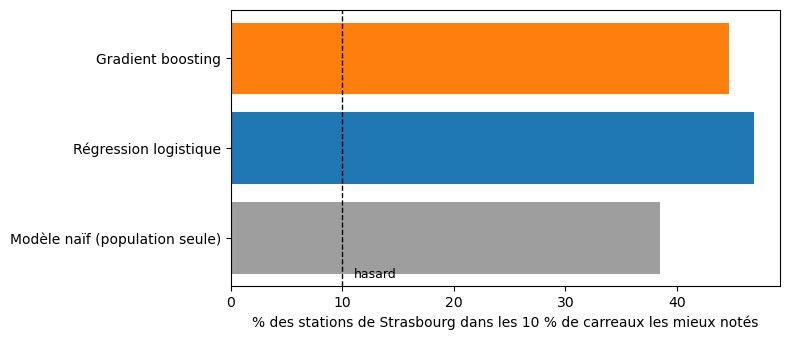

In [ ]:
# 7. Ce que le modèle a appris : poids des variables (régression logistique, variables standardisées)
logit = modeles["Régression logistique"]
poids = pd.DataFrame({"variable": VARIABLES, "poids": logit[-1].coef_[0]}).sort_values("poids", key=abs, ascending=False)
print("Un poids positif pousse vers « quartier type Citiz », un poids négatif vers l'inverse :")
print(poids.round(2).to_string(index=False))
enregistrer(poids, "importance_variables")

# Deux variables très liées se partagent l'effet : leurs poids peuvent être grands et de signes opposés
corr = appr[VARIABLES].corr().abs()
paires = [(a, b, corr.loc[a, b]) for i, a in enumerate(VARIABLES) for b in VARIABLES[i + 1:] if corr.loc[a, b] > 0.8]
if paires:
    print("\nVariables fortement corrélées (poids à interpréter conjointement) :")
    for a, b, v in paires:
        print(f"   {a} et {b} : corrélation {v:.2f}")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(resultats["methode"], 100 * resultats["capture_top10"], color=["#9e9e9e", "#1f77b4", "#ff7f0e"])
ax.axvline(100 * TOP, color="black", linestyle="--", linewidth=1)
ax.text(100 * TOP + 1, -0.45, "hasard", fontsize=9)
ax.set_xlabel("% des stations de Strasbourg dans les 10 % de carreaux les mieux notés")
plt.tight_layout()
plt.savefig(os.path.join(CARTES, "test_strasbourg.png"), dpi=120)
plt.show()

## Interprétation

- **Hasard** : 10 % des stations dans les 10 % de carreaux tirés au hasard.
- **AUC** : 0,5 pour un classement aléatoire, 1 pour un classement parfait.
- **Mesure avec voisins** : une station située dans un carreau adjacent à un carreau du top est comptée. Le gain est rapporté à la part de carreaux couverte par cette zone, afin de ne pas avantager un modèle qui disperse ses choix.
- **Limite** : le modèle apprend la localisation des stations existantes, et non une demande mesurée. Les carreaux sans station ne sont pas nécessairement défavorables (apprentissage positif et non étiqueté, *PU learning*) : le score s'interprète comme un potentiel relatif.